# WaZP Real-Data Catalog

Build a working sample of WaZP clusters that will serve as the **real data** for downstream lensing work. Flow:

1. Load the full WaZP cluster + member catalogs (§1).
2. For every member, compute the projected proper distance `R_MPC` to its parent cluster centre (§2).
3. For every cluster, compute the i-band magnitude gap `DELTA_M_I` from the BCG to the brightest inner satellite (§3), using `destacking.data.magnitude_gaps`.
4. **Then** apply the selection cuts (§4):
   - richness `NGALS > 25`
   - redshift `ZPHOT < 0.7`
   - has a BCG (at least one member row with `FLAG_CG = True`)
5. Save the final compact catalog with `(RA, DEC, NGALS, ZPHOT, DELTA_M_I, DELTA_M_I_ERR)` (§5).

Schema reference (see `data_exploration.ipynb`):

| File | Key columns |
|------|-------------|
| `y6a2_dnf_wazp_v5.0.12.6801_clusters.fits` | `ID`, `RA`, `DEC`, `ZPHOT`, `NGALS`, `RADIUS_MPC` |
| `y6a2_dnf_wazp_v5.0.12.6801_members.fits` | `ID_CLUSTER`, `FLAG_CG`, `PMEM`, `RA`, `DEC`, `MAG_I` |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import warnings
warnings.filterwarnings('ignore')

DATA = '/mnt/c/Users/andre/DATA'
CLUSTERS_FILE = f'{DATA}/y6a2_dnf_wazp_v5.0.12.6801_clusters.fits'
MEMBERS_FILE  = f'{DATA}/y6a2_dnf_wazp_v5.0.12.6801_members.fits'

plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})

## 1 — Load the cluster catalog

In [2]:
with fits.open(CLUSTERS_FILE, memmap=True) as h:
    cl = h[1].data.copy()

print(f'Loaded {len(cl):,} clusters')
print(f'  ZPHOT range: {cl["ZPHOT"].min():.3f} – {cl["ZPHOT"].max():.3f}')
print(f'  NGALS range: {cl["NGALS"].min():.1f} – {cl["NGALS"].max():.1f}')

Loaded 416,947 clusters
  ZPHOT range: 0.027 – 1.317
  NGALS range: 5.0 – 308.8


### Load the full member catalog

We need every column (position, magnitudes, `PMEM`, `FLAG_CG`) for the downstream radial-distance and magnitude-gap computations, so load the whole table.

In [3]:
from astropy.cosmology import Planck18 as COSMO
from astropy import units as u
from astropy.table import Table

with fits.open(MEMBERS_FILE, memmap=True) as h:
    members = Table(h[1].data)

print(f'Loaded member catalog: {len(members):,} rows')
print(f'Columns: {members.colnames}')

Loaded member catalog: 13,133,244 rows
Columns: ['ID', 'ID_CLUSTER', 'RA', 'DEC', 'ZPHOT', 'ZSPEC', 'ZSPEC_SOURCE', 'PMEM', 'FLAG_CG', 'MAG_G', 'MAG_R', 'MAG_I', 'MAG_Z', 'MAG_Y']


## 2 — Projected distance of each member to its cluster centre [Mpc]

For every row in the member catalog we want the proper projected distance to the parent cluster's centre, in Mpc.

Recipe:

1. For each member, look up the parent cluster's `RA`, `DEC`, `ZPHOT` via `ID_CLUSTER -> ID`.
2. Angular separation $\theta$ from the haversine formula on (RA, DEC).
3. Angular diameter distance $D_A(z_{\rm cl})$ from Planck18 — computed once per cluster, then broadcast, since $D_A$ depends only on cluster $z$.
4. Projected proper distance: $R = \theta \cdot D_A$.

We use the WaZP detection centre (`RA`, `DEC`) rather than `RA_CG/DEC_CG`, because the latter are NaN-only in this release. The result is attached to the member table as `R_MPC` and consumed in §3 as the radial argument to `magnitude_gaps`.

In [4]:
# ID -> row-index lookup for clusters.  IDs are dense in [1, len(cl)];
# we build a generic array indexed by ID, with -1 marking 'unknown'.
max_id    = int(cl['ID'].max())
id_to_idx = np.full(max_id + 1, -1, dtype=np.int64)
id_to_idx[cl['ID']] = np.arange(len(cl))

parent_idx  = id_to_idx[np.asarray(members['ID_CLUSTER'])]
n_unmatched = int((parent_idx < 0).sum())
if n_unmatched:
    print(f'WARNING: {n_unmatched:,} member rows reference unknown cluster IDs')

parent_ra  = cl['RA'][parent_idx]
parent_dec = cl['DEC'][parent_idx]
parent_z   = cl['ZPHOT'][parent_idx]

print(f'parent_z range: {parent_z.min():.3f} – {parent_z.max():.3f}')

parent_z range: 0.027 – 1.317


In [5]:
def angsep_rad(ra1, dec1, ra2, dec2):
    """Haversine separation on (RA, Dec) in degrees, returns radians."""
    r1 = np.deg2rad(ra1); d1 = np.deg2rad(dec1)
    r2 = np.deg2rad(ra2); d2 = np.deg2rad(dec2)
    a  = (np.sin((d2 - d1) / 2.0))**2 \
       + np.cos(d1) * np.cos(d2) * (np.sin((r2 - r1) / 2.0))**2
    return 2.0 * np.arcsin(np.sqrt(np.clip(a, 0.0, 1.0)))

theta_rad = angsep_rad(parent_ra, parent_dec,
                       np.asarray(members['RA']), np.asarray(members['DEC']))

# D_A depends only on cluster z, so compute once per cluster then broadcast.
D_A_cluster = COSMO.angular_diameter_distance(cl['ZPHOT']).to_value(u.Mpc)
D_A_member  = D_A_cluster[parent_idx]

r_mpc = (theta_rad * D_A_member).astype('float32')   # proper projected distance [Mpc]

print(f'R_MPC stats:  min={r_mpc.min():.4f}  median={np.median(r_mpc):.3f}  '
      f'p99={np.percentile(r_mpc, 99):.2f}  max={r_mpc.max():.2f}  [Mpc]')

R_MPC stats:  min=0.0001  median=0.365  p99=1.64  max=2.60  [Mpc]


In [6]:
# Sanity checks.
parent_rmpc = cl['RADIUS_MPC'][parent_idx]
inside      = r_mpc <= parent_rmpc
print(f'Members inside parent RADIUS_MPC: {inside.sum():,} / {len(r_mpc):,}  '
      f'({100 * inside.mean():.1f}%)')

bcg = np.asarray(members['FLAG_CG'])
print(f'BCG (FLAG_CG=True) rows:        {bcg.sum():,}')
print(f'  median R_MPC of BCG rows:     {np.median(r_mpc[bcg]):.4f}  Mpc')
print(f'  99th-pct R_MPC of BCG rows:   {np.percentile(r_mpc[bcg], 99):.4f}  Mpc')

Members inside parent RADIUS_MPC: 12,797,016 / 13,133,244  (97.4%)
BCG (FLAG_CG=True) rows:        336,379
  median R_MPC of BCG rows:     0.0851  Mpc
  99th-pct R_MPC of BCG rows:   0.2936  Mpc


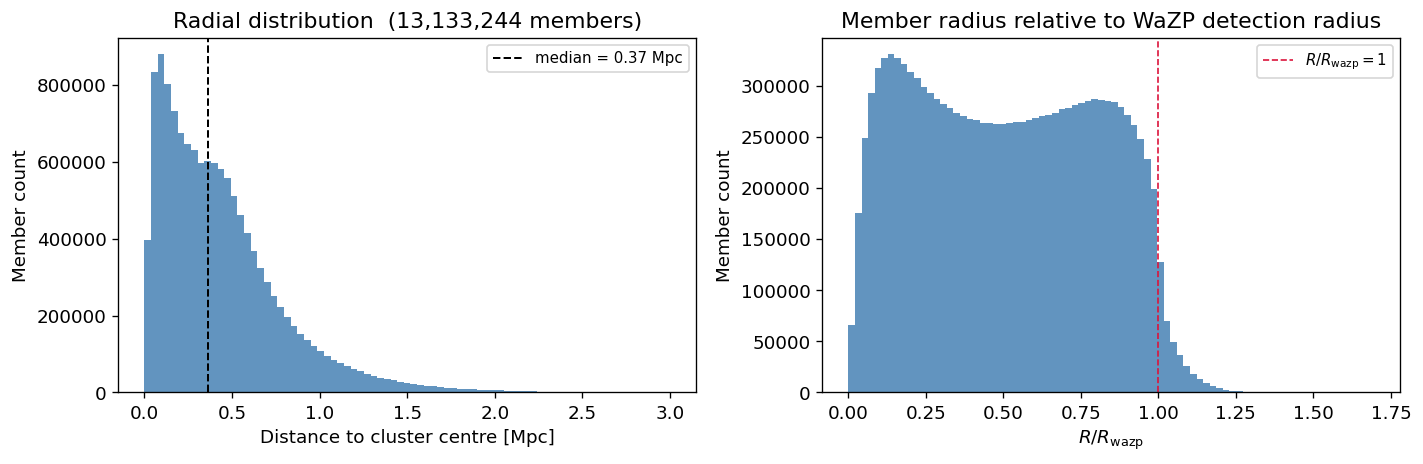

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.hist(r_mpc, bins=np.linspace(0, 3, 80), color='steelblue',
        edgecolor='none', alpha=0.85)
ax.axvline(np.median(r_mpc), color='k', ls='--', lw=1.2,
           label=f'median = {np.median(r_mpc):.2f} Mpc')
ax.set_xlabel('Distance to cluster centre [Mpc]')
ax.set_ylabel('Member count')
ax.set_title(f'Radial distribution  ({len(r_mpc):,} members)')
ax.legend(fontsize=9)

ax = axes[1]
ratio = r_mpc / np.maximum(parent_rmpc, 1e-6)
ax.hist(ratio[ratio < 4], bins=80, color='steelblue', edgecolor='none', alpha=0.85)
ax.axvline(1.0, color='crimson', ls='--', lw=1.0,
           label=r'$R / R_{\rm wazp} = 1$')
ax.set_xlabel(r'$R / R_{\rm wazp}$')
ax.set_ylabel('Member count')
ax.set_title('Member radius relative to WaZP detection radius')
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

In [8]:
members['R_MPC'] = r_mpc
members['R_MPC'].unit        = u.Mpc
members['R_MPC'].description = (
    'Projected proper distance from member (RA,DEC) to parent cluster '
    '(RA,DEC) at cluster ZPHOT, computed with astropy Planck18.'
)
print(members[['ID', 'ID_CLUSTER', 'RA', 'DEC', 'FLAG_CG', 'R_MPC']][:10])

    ID    ID_CLUSTER     RA        DEC     FLAG_CG   R_MPC   
                                                      Mpc    
--------- ---------- ---------- ---------- ------- ----------
931290308     263257 326.241184 -39.706638   False 0.08932014
931291962     206535 326.267856 -39.735749   False  0.3588687
931291646     206535 326.261752 -39.729913   False 0.18867218
931291429     206535 326.262462 -39.725864   False 0.07602269
931291778     206535 326.279988 -39.732492   False 0.43569475
931291067     206535 326.284384 -39.719324   False 0.48329988
938500083     291832 327.665321 -40.189707   False 0.48477188
938498376     291832 327.693301 -40.171027   False 0.11223212
938504711      11924 327.949169 -40.241696   False  1.3698782
938501687      11924 327.898442 -40.209677   False  1.4002428


## 3 — Magnitude gap per cluster (i-band)

For each cluster we compute the expected magnitude gap between the BCG (the `FLAG_CG=True` member) and the brightest satellite within `r_cut = 0.5 Mpc`, using

```python
from destacking.data import magnitude_gaps
```

The function weights each candidate "brightest satellite" by the probability that it is a member *and* every brighter satellite is not — i.e. an expected gap marginalised over membership uncertainty (via `PMEM`).

Inputs per cluster:
- `mag_bcg`  → BCG `MAG_I`
- `mag_mem`  → satellite `MAG_I` values
- `p_mem`    → satellite `PMEM`
- `r_mem`    → satellite `R_MPC` (the column we just added)

Clusters with no BCG row, or no satellites inside `r_cut`, get `NaN`.

In [9]:
from destacking.data import magnitude_gaps
import time

# Sort members by ID_CLUSTER so each cluster's rows are contiguous.
# This lets us slice with a single np.searchsorted lookup instead of
# 400k boolean comparisons.
mem_idc = np.asarray(members['ID_CLUSTER'])
order   = np.argsort(mem_idc, kind='stable')
mem_idc_s = mem_idc[order]
mag_i_s   = np.asarray(members['MAG_I'])[order]
pmem_s    = np.asarray(members['PMEM'])[order]
r_mpc_s   = np.asarray(members['R_MPC'])[order]
bcg_s     = np.asarray(members['FLAG_CG'])[order]

# Boundaries of each cluster's run in the sorted arrays.
edges = np.searchsorted(mem_idc_s, cl['ID'], side='left'), \
        np.searchsorted(mem_idc_s, cl['ID'], side='right')
start_idx, end_idx = edges

R_CUT = 0.5  # Mpc, inner satellite cut
print(f'Computing magnitude gap for {len(cl):,} clusters in i-band, '
      f'r_cut = {R_CUT} Mpc')

Lookup tables loaded!
Computing magnitude gap for 416,947 clusters in i-band, r_cut = 0.5 Mpc


In [10]:
delta_m   = np.full(len(cl), np.nan, dtype='float64')
delta_m_e = np.full(len(cl), np.nan, dtype='float64')

t0 = time.time()
for k in range(len(cl)):
    s, e = start_idx[k], end_idx[k]
    if e == s:
        continue                       # cluster has no members in the catalog

    bcg_mask = bcg_s[s:e]
    if not bcg_mask.any():
        continue                       # no BCG row

    bcg_pos = s + int(np.argmax(bcg_mask))
    mag_bcg = mag_i_s[bcg_pos]

    sat_slice = np.r_[s:bcg_pos, bcg_pos + 1:e]
    if sat_slice.size == 0:
        continue

    mag_gap, mag_gap_e = magnitude_gaps(
        mag_bcg,
        mag_i_s[sat_slice],
        pmem_s [sat_slice],
        r_mpc_s[sat_slice],
        r_cut=R_CUT,
    )
    delta_m[k]   = mag_gap
    delta_m_e[k] = mag_gap_e

    if (k + 1) % 20000 == 0 or (k + 1) == len(cl):
        dt = time.time() - t0
        print(f'  {k+1:>6,}/{len(cl):,}  '
              f'elapsed {dt:6.1f}s  eta {dt/(k+1)*(len(cl)-k-1):6.1f}s',
              flush=True)

print(f'\nFinished in {time.time()-t0:.1f} s')
print(f'  clusters with a finite gap: {np.isfinite(delta_m).sum():,}  '
      f'({100*np.isfinite(delta_m).mean():.1f}%)')

  20,000/416,947  elapsed    4.1s  eta   81.1s
  60,000/416,947  elapsed   12.3s  eta   73.3s
  80,000/416,947  elapsed   16.4s  eta   68.9s
  100,000/416,947  elapsed   20.4s  eta   64.7s
  140,000/416,947  elapsed   32.2s  eta   63.7s
  160,000/416,947  elapsed   36.3s  eta   58.4s
  180,000/416,947  elapsed   40.5s  eta   53.3s
  200,000/416,947  elapsed   44.6s  eta   48.4s
  260,000/416,947  elapsed   61.0s  eta   36.8s
  280,000/416,947  elapsed   65.4s  eta   32.0s
  300,000/416,947  elapsed   70.0s  eta   27.3s
  320,000/416,947  elapsed   74.5s  eta   22.6s
  340,000/416,947  elapsed   79.2s  eta   17.9s
  360,000/416,947  elapsed   84.0s  eta   13.3s
  400,000/416,947  elapsed   97.8s  eta    4.1s
  416,947/416,947  elapsed  103.1s  eta    0.0s

Finished in 103.1 s
  clusters with a finite gap: 336,379  (80.7%)


In [11]:
finite = np.isfinite(delta_m)
print('Δm (i-band) statistics over clusters with finite values:')
print(f'  N          : {finite.sum():,}')
print(f'  mean       : {delta_m[finite].mean():+.3f}  mag')
print(f'  median     : {np.median(delta_m[finite]):+.3f}  mag')
print(f'  std        : {delta_m[finite].std():.3f}  mag')
print(f'  16/84 pct  : {np.percentile(delta_m[finite], 16):+.3f}  /  '
      f'{np.percentile(delta_m[finite], 84):+.3f}  mag')
print(f'  min / max  : {delta_m[finite].min():+.3f}  /  '
      f'{delta_m[finite].max():+.3f}  mag')

Δm (i-band) statistics over clusters with finite values:
  N          : 336,379
  mean       : +0.620  mag
  median     : +0.517  mag
  std        : 0.513  mag
  16/84 pct  : +0.140  /  +1.133  mag
  min / max  : -2.203  /  +4.189  mag


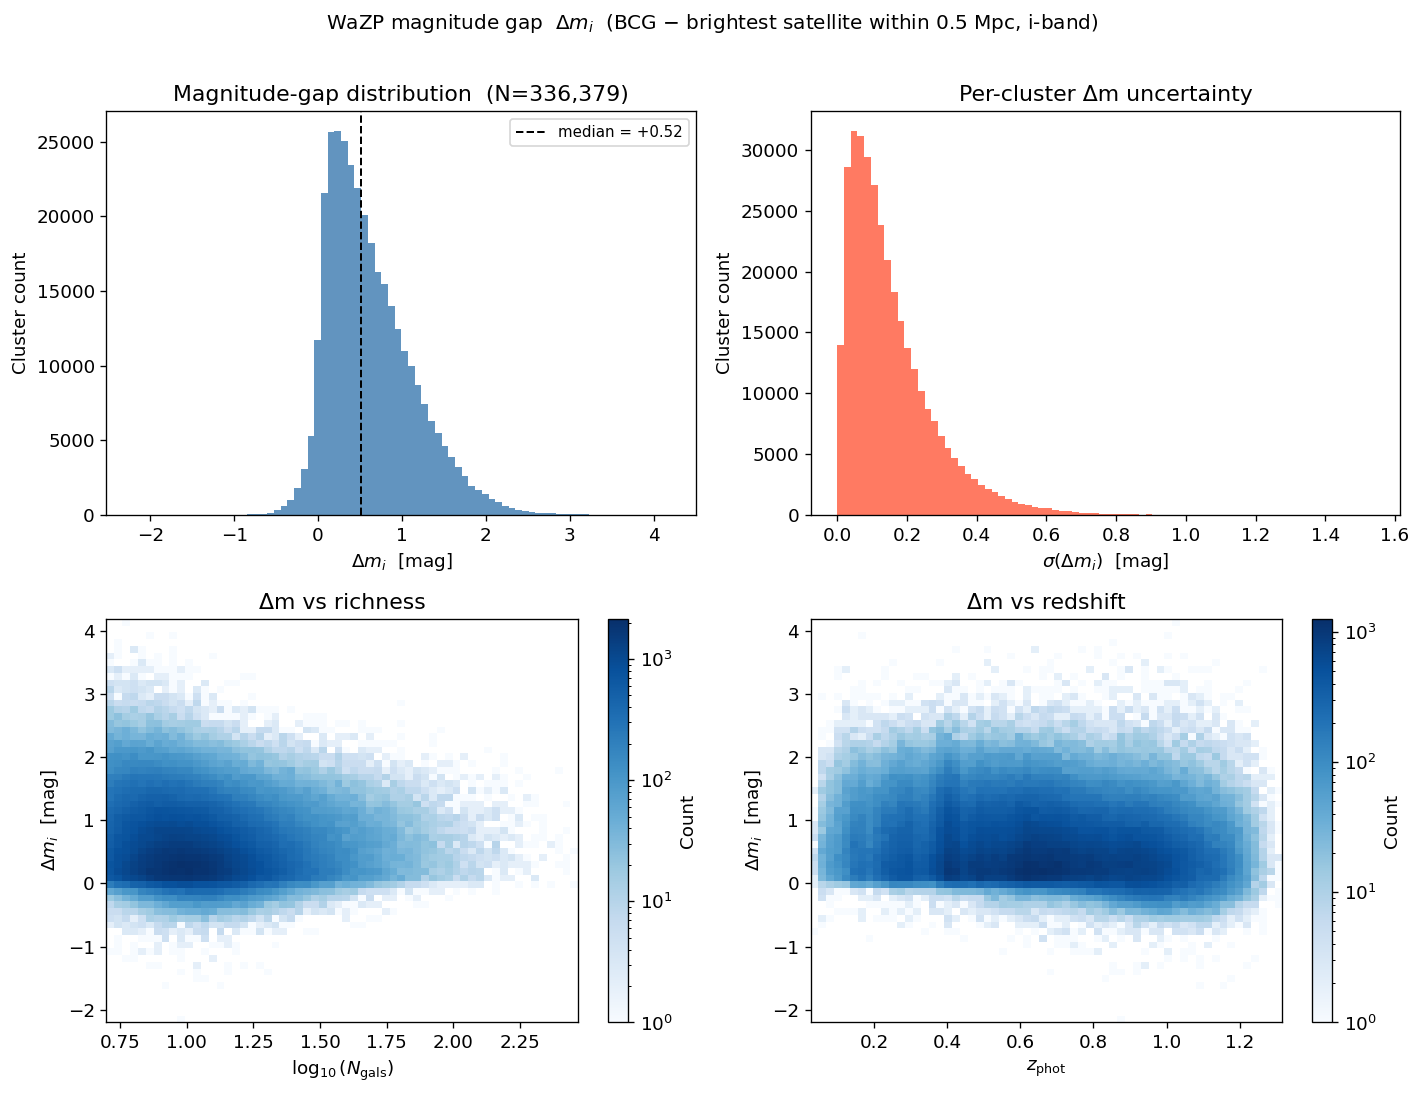

In [12]:
import matplotlib.colors as mcolors

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

dm_finite   = delta_m[finite]
dme_finite  = delta_m_e[finite]
z_finite    = cl['ZPHOT'][finite]
n_finite    = cl['NGALS'][finite]

# 1. Δm histogram
ax = axes[0, 0]
ax.hist(dm_finite, bins=80, color='steelblue', edgecolor='none', alpha=0.85)
ax.axvline(np.median(dm_finite), color='k', ls='--', lw=1.2,
           label=f'median = {np.median(dm_finite):+.2f}')
ax.set_xlabel(r'$\Delta m_i$  [mag]')
ax.set_ylabel('Cluster count')
ax.set_title(f'Magnitude-gap distribution  (N={finite.sum():,})')
ax.legend(fontsize=9)

# 2. Δm uncertainty histogram
ax = axes[0, 1]
ax.hist(dme_finite[np.isfinite(dme_finite)], bins=80,
        color='tomato', edgecolor='none', alpha=0.85)
ax.set_xlabel(r'$\sigma(\Delta m_i)$  [mag]')
ax.set_ylabel('Cluster count')
ax.set_title('Per-cluster Δm uncertainty')

# 3. Δm vs richness
ax = axes[1, 0]
h2, xe, ye, im = ax.hist2d(
    np.log10(n_finite), dm_finite,
    bins=[60, 60], cmap='Blues', norm=mcolors.LogNorm(),
)
plt.colorbar(im, ax=ax, label='Count')
ax.set_xlabel(r'$\log_{10}(N_{\rm gals})$')
ax.set_ylabel(r'$\Delta m_i$  [mag]')
ax.set_title('Δm vs richness')

# 4. Δm vs redshift
ax = axes[1, 1]
h2, xe, ye, im = ax.hist2d(
    z_finite, dm_finite,
    bins=[60, 60], cmap='Blues', norm=mcolors.LogNorm(),
)
plt.colorbar(im, ax=ax, label='Count')
ax.set_xlabel(r'$z_{\rm phot}$')
ax.set_ylabel(r'$\Delta m_i$  [mag]')
ax.set_title('Δm vs redshift')

plt.suptitle(
    r'WaZP magnitude gap  $\Delta m_i$  '
    r'(BCG $-$ brightest satellite within 0.5 Mpc, i-band)',
    fontsize=12, y=1.01,
)
plt.tight_layout()
plt.show()

In [19]:
np.log10(300)

np.float64(2.4771212547196626)

In [13]:
# Attach Δm and its uncertainty to the cluster catalog (as a Table).
cl_tab = Table(cl)
cl_tab['DELTA_M_I']     = delta_m.astype('float32')
cl_tab['DELTA_M_I_ERR'] = delta_m_e.astype('float32')
cl_tab['DELTA_M_I'].unit         = u.mag
cl_tab['DELTA_M_I_ERR'].unit     = u.mag
cl_tab['DELTA_M_I'].description  = (
    'Expected magnitude gap (BCG - brightest satellite) in i-band within '
    '0.5 Mpc, weighted by PMEM via destacking.data.magnitude_gaps.'
)
cl_tab['DELTA_M_I_ERR'].description = 'sqrt(Var) of the i-band magnitude gap.'
print(f'Cluster table now has {len(cl_tab.colnames)} columns including '
      f'DELTA_M_I, DELTA_M_I_ERR.')

Cluster table now has 24 columns including DELTA_M_I, DELTA_M_I_ERR.


## 4 — Selection cuts

Apply the three cuts from the intro: richness `NGALS > 25`, redshift `ZPHOT < 0.7`, and presence of a BCG. The BCG-presence check uses the member catalog: a cluster passes iff at least one of its member rows has `FLAG_CG = True`.

We track survival per cut, and additionally report how many surviving clusters have a finite `DELTA_M_I` (a cluster may pass the BCG cut but still have no satellites within 0.5 Mpc, leaving the gap undefined).

In [15]:
# Set of cluster IDs that contain at least one BCG-flagged member.
bcg_cluster_ids = np.unique(
    np.asarray(members['ID_CLUSTER'])[np.asarray(members['FLAG_CG'])]
)

cut_richness = cl_tab['NGALS'] > 25
cut_z        = cl_tab['ZPHOT'] < 0.7
cut_has_bcg  = np.isin(cl_tab['ID'], bcg_cluster_ids)
selection    = cut_richness & cut_z & cut_has_bcg

selected = cl_tab[selection]
N0 = len(cl_tab)

print(f'{"Cut":<40}  Surviving        Pct')
print('-' * 70)
print(f'{"Total clusters":<40}  {N0:>9,}      {100.0:6.2f}%')
print(f'{"NGALS > 25":<40}  {int(cut_richness.sum()):>9,}      {100*cut_richness.sum()/N0:6.2f}%')
print(f'{"ZPHOT < 0.7":<40}  {int(cut_z.sum()):>9,}      {100*cut_z.sum()/N0:6.2f}%')
print(f'{"has BCG (FLAG_CG=True in members)":<40}  {int(cut_has_bcg.sum()):>9,}      {100*cut_has_bcg.sum()/N0:6.2f}%')
print('-' * 70)
print(f'{"All three cuts":<40}  {int(selection.sum()):>9,}      {100*selection.sum()/N0:6.2f}%')
print(f'{"  ...with finite DELTA_M_I":<40}  '
      f'{int(np.isfinite(selected["DELTA_M_I"]).sum()):>9,}')

Cut                                       Surviving        Pct
----------------------------------------------------------------------
Total clusters                              416,947      100.00%
NGALS > 25                                   42,322       10.15%
ZPHOT < 0.7                                 237,975       57.08%
has BCG (FLAG_CG=True in members)           336,379       80.68%
----------------------------------------------------------------------
All three cuts                               15,967        3.83%
  ...with finite DELTA_M_I                   15,967


## 5 — Final "real-data" catalog

Build a compact table with only the columns we'll use downstream: position (RA, DEC), richness (NGALS), redshift (ZPHOT), and magnitude gap with its uncertainty (DELTA_M_I, DELTA_M_I_ERR). The original `ID` is kept so we can cross-match back to the full WaZP catalog when needed.

In [16]:
import os

final = Table()
final['ID']            = selected['ID']
final['RA']            = selected['RA']
final['DEC']           = selected['DEC']
final['NGALS']         = selected['NGALS']
final['ZPHOT']         = selected['ZPHOT']
final['DELTA_M_I']     = selected['DELTA_M_I']
final['DELTA_M_I_ERR'] = selected['DELTA_M_I_ERR']

OUT_FINAL = 'data/wazp_real_data.fits'
os.makedirs(os.path.dirname(OUT_FINAL), exist_ok=True)
final.write(OUT_FINAL, overwrite=True)

print(f'Wrote {len(final):,} cluster rows to {OUT_FINAL}')
print(f'Columns: {final.colnames}\n')
print('First 10 rows:')
print(final[:10])

Wrote 15,967 cluster rows to data/wazp_real_data.fits
Columns: ['ID', 'RA', 'DEC', 'NGALS', 'ZPHOT', 'DELTA_M_I', 'DELTA_M_I_ERR']

First 10 rows:
  ID           RA                 DEC         ... DELTA_M_I  DELTA_M_I_ERR
                                              ...    mag          mag     
------ ------------------ ------------------- ... ---------- -------------
415758  87.73631813660649  -32.97923751193601 ... 0.26683775    0.22839953
415518  62.75974626646493 -56.633235184916956 ...  0.6855709    0.07501159
414945 310.25610580138476  -45.74450343847707 ...  1.4896938    0.12350717
414017  73.34790282022509 -43.877281720038674 ...  0.6803682    0.18163316
413027  28.57451589169451  -20.79654423941566 ... 0.46535033    0.03589241
412863 58.890697762146914  -32.77563718391527 ... 0.62559426    0.21426119
412478 58.525009482322744  -37.98756501369641 ...  1.2190822   0.036353186
411964 315.12940417602573  -59.45636657096096 ... 0.10238094    0.09896276
409766  52.98665207845768 -2